# Taller 2 — Resolver un ambiente nuevo de Gymnasium con DQN

**Presentado por:**
- Ernesto Ilich Contreras Hernandez.
- Jesus Gabriel Castillo Malaver.
- Noel Eduardo Perez Barrios.
- Paola Andrea Roa Molina.
- Ruslan Valery Yaya Chujmanov.
- Victor Enrique Cantor Beltran.

**Ambiente seleccionado:** `Acrobot-v1`  
**Algoritmo:** Deep Q-Network (DQN)

Este notebook está diseñado para cubrir explícitamente la rúbrica: acciones/observaciones, flujo DQN y particularidades, red neuronal, resultados, reflexión de resultados y reflexión de dificultades.

## 1. Instalación
En Google Colab ejecute esta celda una sola vez.

In [1]:
!pip -q install "gymnasium[classic-control]" "stable-baselines3[extra]"

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 12.1/12.1 MB 32.9 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 187.6/187.6 kB 7.7 MB/s eta 0:00:00


## 2. Importaciones, semilla y carpetas

In [2]:
import os, json, random
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import gymnasium as gym
import torch
from stable_baselines3 import DQN
from stable_baselines3.common.monitor import Monitor
from stable_baselines3.common.results_plotter import load_results, ts2xy

SEED = 42
ENV_ID = "Acrobot-v1"
random.seed(SEED); np.random.seed(SEED); torch.manual_seed(SEED)
RESULTS_DIR = Path("results"); MODELS_DIR = Path("models"); LOG_DIR = Path("logs_dqn")
RESULTS_DIR.mkdir(exist_ok=True); MODELS_DIR.mkdir(exist_ok=True); LOG_DIR.mkdir(exist_ok=True)
print("Entorno:", ENV_ID, "| Semilla:", SEED)

Entorno: Acrobot-v1 | Semilla: 42


Gym has been unmaintained since 2022 and does not support NumPy 2.0 amongst other critical functionality.
Please upgrade to Gymnasium, the maintained drop-in replacement of Gym, or contact the authors of your software and request that they upgrade.
See the migration guide at https://gymnasium.farama.org/introduction/migration_guide/ for additional information.
/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)


## 3. Acciones, observaciones y recompensas

`Acrobot-v1` representa dos eslabones articulados. El objetivo es aplicar torque para elevar el extremo libre por encima de una altura objetivo.

**Observación:** `Box`, forma `(6,)`, `float32`:
1. `cos(theta1)`
2. `sin(theta1)`
3. `cos(theta2)`
4. `sin(theta2)`
5. velocidad angular de `theta1`
6. velocidad angular de `theta2`

No se utilizan imágenes, por lo que no se requiere frame stacking ni convoluciones. La representación seno/coseno evita una discontinuidad angular.

**Acciones:** `Discrete(3)`:
- `0`: torque -1
- `1`: torque 0
- `2`: torque +1

**Recompensa:** -1 por cada paso que no alcanza la meta y 0 al alcanzar el objetivo. Por ello, retornos menos negativos son mejores. El episodio se trunca a 500 pasos.

In [3]:
env_check = gym.make(ENV_ID)
print("Espacio de observación:", env_check.observation_space)
print("Shape:", env_check.observation_space.shape)
print("dtype:", env_check.observation_space.dtype)
print("Límite inferior:", env_check.observation_space.low)
print("Límite superior:", env_check.observation_space.high)
print("Espacio de acciones:", env_check.action_space)
obs, info = env_check.reset(seed=SEED)
print("Observación inicial:", obs)
env_check.close()

Espacio de observación: Box([ -1.        -1.        -1.        -1.       -12.566371 -28.274334], [ 1.        1.        1.        1.       12.566371 28.274334], (6,), float32)
Shape: (6,)
dtype: float32
Límite inferior: [ -1.        -1.        -1.        -1.       -12.566371 -28.274334]
Límite superior: [ 1.        1.        1.        1.       12.566371 28.274334]
Espacio de acciones: Discrete(3)
Observación inicial: [ 0.99849933  0.0547638   0.99992526 -0.01222401  0.07171959  0.0394736 ]


## 4. Baseline: política aleatoria
Se evalúa una política sin aprendizaje para disponer de una referencia cuantitativa.

In [4]:
def evaluate_random_policy(env_id, n_episodes=50, seed=42):
    returns, lengths, successes = [], [], []
    for ep in range(n_episodes):
        env = gym.make(env_id)
        env.action_space.seed(seed + ep)
        obs, _ = env.reset(seed=seed + ep)
        terminated = truncated = False
        ret = 0.0; length = 0
        while not (terminated or truncated):
            action = env.action_space.sample()
            obs, reward, terminated, truncated, _ = env.step(action)
            ret += float(reward); length += 1
        returns.append(ret); lengths.append(length); successes.append(bool(terminated))
        env.close()
    return np.asarray(returns), np.asarray(lengths), np.asarray(successes)

baseline_returns, baseline_lengths, baseline_successes = evaluate_random_policy(ENV_ID, 50, SEED)
baseline_summary = {
    "retorno_promedio": float(baseline_returns.mean()),
    "desviacion_estandar": float(baseline_returns.std(ddof=1)),
    "retorno_minimo": float(baseline_returns.min()),
    "retorno_maximo": float(baseline_returns.max()),
    "longitud_promedio": float(baseline_lengths.mean()),
    "tasa_exito": float(baseline_successes.mean()),
}
pd.DataFrame([baseline_summary])

,retorno_promedio,desviacion_estandar,retorno_minimo,retorno_maximo,longitud_promedio,tasa_exito
0,-500.0,0.0,-500.0,-500.0,500.0,0.0


/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)


## 5. Flujo de entrenamiento DQN y particularidades

```text
Estado s → Red Q online → acción ε-greedy → entorno → transición (s,a,r,s',done)
→ replay buffer → mini-lote → objetivo Bellman con red target → pérdida TD
→ backpropagation → actualización red online → sincronización periódica target
```

**Particularidades:** observación continua de 6 variables, 3 acciones discretas, recompensa -1 por paso, necesidad de acumular energía mediante oscilaciones y límite de 500 pasos. La exploración ε-greedy es importante porque una secuencia útil de torques no es evidente desde el inicio.

## 6. Red neuronal e hiperparámetros

Arquitectura: **6 → 256 ReLU → 256 ReLU → 3 valores Q**. La salida contiene un valor Q por acción. Una MLP es apropiada porque la entrada es vectorial, no visual.

In [5]:
HYPERPARAMS = {
    "learning_rate": 6.3e-4,
    "buffer_size": 50_000,
    "learning_starts": 0,
    "batch_size": 128,
    "gamma": 0.99,
    "target_update_interval": 250,
    "train_freq": 4,
    "gradient_steps": -1,
    "exploration_fraction": 0.12,
    "exploration_initial_eps": 1.0,
    "exploration_final_eps": 0.10,
    "net_arch": [256, 256],
    "total_timesteps": 100_000,
}
pd.DataFrame([{"hiperparametro":k,"valor":str(v)} for k,v in HYPERPARAMS.items()])

,hiperparametro,valor
0,learning_rate,0.00063
1,buffer_size,50000
2,learning_starts,0
3,batch_size,128
4,gamma,0.99
5,target_update_interval,250
6,train_freq,4
7,gradient_steps,-1
8,exploration_fraction,0.12
9,exploration_initial_eps,1.0


/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)


**Justificación de la arquitectura y los hiperparámetros**

- `learning_rate=6.3e-4`: tamaño de paso moderado para actualizar la red sin producir cambios excesivamente bruscos.
- `buffer_size=50_000`: conserva un conjunto amplio de transiciones y reduce la correlación temporal entre muestras consecutivas.
- `learning_starts=0`: permite comenzar a actualizar desde el inicio. Es una elección agresiva, pero en esta ejecución funcionó con la exploración inicial alta; como limitación, un valor mayor podría dar más diversidad al buffer antes de aprender.
- `batch_size=128`: ofrece un compromiso entre estabilidad del gradiente y costo computacional.
- `gamma=0.99`: da alto peso a consecuencias futuras, necesario porque Acrobot debe acumular energía durante varios pasos antes de alcanzar la meta.
- `target_update_interval=250`: mantiene la red objetivo fija durante intervalos cortos para estabilizar el objetivo de Bellman.
- `train_freq=4`: realiza entrenamiento cada cuatro pasos de interacción, evitando una actualización en cada transición.
- `gradient_steps=-1`: hace que el número de pasos de gradiente se adapte a la cantidad de pasos recolectados en cada bloque de entrenamiento.
- `exploration_fraction=0.12`, `epsilon: 1.0 → 0.1`: favorece una exploración amplia al inicio y una explotación progresiva de la política aprendida.
- `net_arch=[256,256]`: dos capas densas ReLU son suficientes para aproximar Q(s,a) a partir de seis variables continuas sin recurrir a convoluciones.
- `total_timesteps=100_000`: presupuesto de entrenamiento usado para lograr convergencia práctica dentro del alcance del taller.


In [6]:
train_env = Monitor(gym.make(ENV_ID), str(LOG_DIR))
model = DQN(
    "MlpPolicy", train_env,
    learning_rate=HYPERPARAMS["learning_rate"],
    buffer_size=HYPERPARAMS["buffer_size"],
    learning_starts=HYPERPARAMS["learning_starts"],
    batch_size=HYPERPARAMS["batch_size"],
    gamma=HYPERPARAMS["gamma"],
    target_update_interval=HYPERPARAMS["target_update_interval"],
    train_freq=HYPERPARAMS["train_freq"],
    gradient_steps=HYPERPARAMS["gradient_steps"],
    exploration_fraction=HYPERPARAMS["exploration_fraction"],
    exploration_initial_eps=HYPERPARAMS["exploration_initial_eps"],
    exploration_final_eps=HYPERPARAMS["exploration_final_eps"],
    policy_kwargs=dict(net_arch=HYPERPARAMS["net_arch"]),
    verbose=1, seed=SEED, device="auto"
)
print(model.policy)

Using cpu device
Wrapping the env in a DummyVecEnv.
DQNPolicy(
  (q_net): QNetwork(
    (features_extractor): FlattenExtractor(
      (flatten): Flatten(start_dim=1, end_dim=-1)
    )
    (q_net): Sequential(
      (0): Linear(in_features=6, out_features=256, bias=True)
      (1): ReLU()
      (2): Linear(in_features=256, out_features=256, bias=True)
      (3): ReLU()
      (4): Linear(in_features=256, out_features=3, bias=True)
    )
  )
  (q_net_target): QNetwork(
    (features_extractor): FlattenExtractor(
      (flatten): Flatten(start_dim=1, end_dim=-1)
    )
    (q_net): Sequential(
      (0): Linear(in_features=6, out_features=256, bias=True)
      (1): ReLU()
      (2): Linear(in_features=256, out_features=256, bias=True)
      (3): ReLU()
      (4): Linear(in_features=256, out_features=3, bias=True)
    )
  )
)


/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)


## 7. Entrenamiento

In [7]:
# 7. Entrenamiento

TOTAL_TIMESTEPS = HYPERPARAMS["total_timesteps"]

print(f"Iniciando entrenamiento DQN durante {TOTAL_TIMESTEPS:,} timesteps...")

model.learn(
    total_timesteps=TOTAL_TIMESTEPS,
    progress_bar=False
)

model.save(MODELS_DIR / "dqn_acrobot")
train_env.close()

print("Entrenamiento finalizado correctamente.")
print("Modelo guardado en: models/dqn_acrobot.zip")

Iniciando entrenamiento DQN durante 100,000 timesteps...
----------------------------------
| rollout/            |          |
|    ep_len_mean      | 500      |
|    ep_rew_mean      | -500     |
|    exploration_rate | 0.85     |
| time/               |          |
|    episodes         | 4        |
|    fps              | 201      |
|    time_elapsed     | 9        |
|    total_timesteps  | 2000     |
| train/              |          |
|    learning_rate    | 0.00063  |
|    loss             | 0.0015   |
|    n_updates        | 1996     |
----------------------------------
----------------------------------
| rollout/            |          |
|    ep_len_mean      | 500      |
|    ep_rew_mean      | -500     |
|    exploration_rate | 0.7      |
| time/               |          |
|    episodes         | 8        |
|    fps              | 209      |
|    time_elapsed     | 19       |
|    total_timesteps  | 4000     |
| train/              |          |
|    learning_rate    | 0.00063  

## 8. Curva de aprendizaje
Una tendencia hacia retornos menos negativos indica que el agente alcanza la meta en menos pasos.

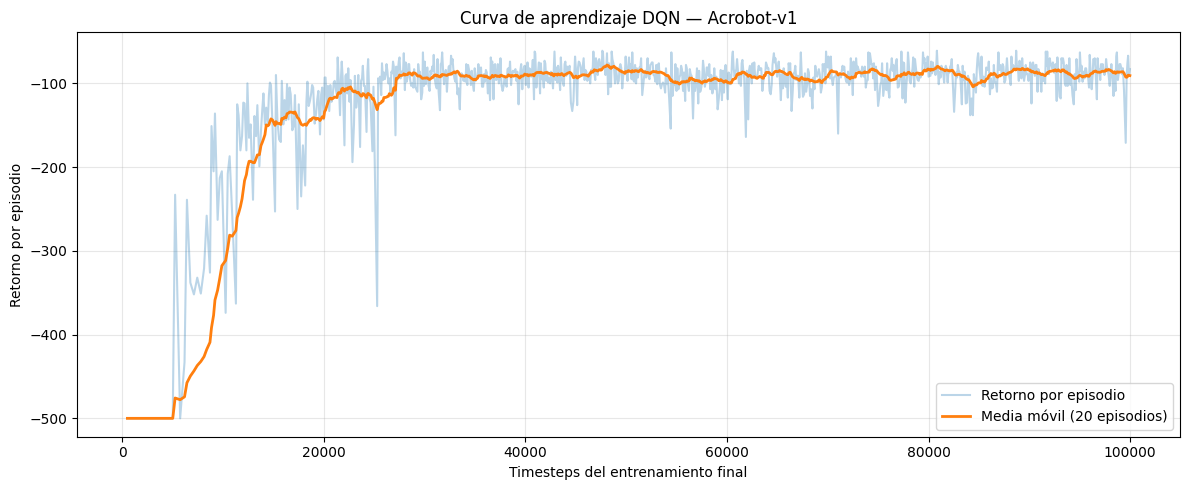

Timesteps considerados: 500 a 99971


/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)


,timesteps,episode_return,media_movil_20
956,99651,-91.0,-92.75
957,99728,-76.0,-92.00
958,99796,-67.0,-90.20
959,99887,-90.0,-90.40
960,99971,-83.0,-90.70


In [8]:
# 8. Curva de aprendizaje corregida
# Conserva únicamente el entrenamiento final de 100.000 timesteps

from stable_baselines3.common.results_plotter import load_results, ts2xy
import pandas as pd
import matplotlib.pyplot as plt

monitor_df = load_results(str(LOG_DIR))
timesteps, episode_returns = ts2xy(monitor_df, "timesteps")

learning_df = pd.DataFrame({
    "timesteps": timesteps,
    "episode_return": episode_returns
})

# Tomar únicamente el entrenamiento final
TOTAL_TIMESTEPS = HYPERPARAMS["total_timesteps"]

ultimo_timestep = learning_df["timesteps"].max()

inicio_entrenamiento_final = max(
    0,
    ultimo_timestep - TOTAL_TIMESTEPS
)

learning_df = learning_df[
    learning_df["timesteps"] > inicio_entrenamiento_final
].copy()

# Reiniciar el eje temporal del entrenamiento final
learning_df["timesteps"] = (
    learning_df["timesteps"] - inicio_entrenamiento_final
)

# Media móvil de 20 episodios
learning_df["media_movil_20"] = (
    learning_df["episode_return"]
    .rolling(window=20, min_periods=1)
    .mean()
)

# Guardar CSV
learning_df.to_csv(
    RESULTS_DIR / "dqn_learning_curve.csv",
    index=False
)

# Generar gráfica
plt.figure(figsize=(12, 5))

plt.plot(
    learning_df["timesteps"],
    learning_df["episode_return"],
    alpha=0.30,
    label="Retorno por episodio"
)

plt.plot(
    learning_df["timesteps"],
    learning_df["media_movil_20"],
    linewidth=2,
    label="Media móvil (20 episodios)"
)

plt.title("Curva de aprendizaje DQN — Acrobot-v1")
plt.xlabel("Timesteps del entrenamiento final")
plt.ylabel("Retorno por episodio")

plt.legend()
plt.grid(alpha=0.3)
plt.tight_layout()

plt.savefig(
    RESULTS_DIR / "dqn_learning_curve.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

print(
    f"Timesteps considerados: "
    f"{learning_df['timesteps'].min():.0f} "
    f"a {learning_df['timesteps'].max():.0f}"
)

display(learning_df.tail())

## 9. Evaluación final del agente

In [9]:
# ============================================================
# 9. Evaluación final del agente DQN
# ============================================================

import gymnasium as gym
import numpy as np
import pandas as pd
from pathlib import Path

ENV_ID = "Acrobot-v1"
SEED = 42
N_EVAL_EPISODES = 30

RESULTS_DIR = Path("results")
RESULTS_DIR.mkdir(parents=True, exist_ok=True)

returns = []
episode_lengths = []
successes = []

for episode in range(N_EVAL_EPISODES):
    env = gym.make(ENV_ID)
    obs, info = env.reset(seed=SEED + episode)
    terminated = False
    truncated = False
    episode_return = 0.0
    episode_length = 0

    while not (terminated or truncated):
        action, _ = model.predict(obs, deterministic=True)
        obs, reward, terminated, truncated, info = env.step(action)
        episode_return += float(reward)
        episode_length += 1

    returns.append(episode_return)
    episode_lengths.append(episode_length)
    successes.append(bool(terminated))  # En Acrobot, terminated=True implica alcanzar la meta
    env.close()

returns = np.asarray(returns, dtype=float)
episode_lengths = np.asarray(episode_lengths, dtype=int)
successes = np.asarray(successes, dtype=bool)

evaluation_df = pd.DataFrame({
    "episodio": np.arange(1, N_EVAL_EPISODES + 1),
    "retorno": returns,
    "longitud": episode_lengths,
    "exito": successes.astype(int),
})
evaluation_df.to_csv(RESULTS_DIR / "dqn_evaluation.csv", index=False)

dqn_returns = returns.copy()
dqn_summary = {
    "retorno_promedio": float(returns.mean()),
    "desviacion_estandar": float(returns.std(ddof=1)),
    "retorno_minimo": float(returns.min()),
    "retorno_maximo": float(returns.max()),
    "longitud_promedio": float(episode_lengths.mean()),
    "tasa_exito": float(successes.mean()),
}

evaluation_summary = pd.DataFrame({
    "Métrica": [
        "Episodios evaluados", "Retorno promedio", "Desviación estándar",
        "Retorno mínimo", "Retorno máximo", "Longitud promedio", "Tasa de éxito"
    ],
    "Valor": [
        N_EVAL_EPISODES,
        dqn_summary["retorno_promedio"],
        dqn_summary["desviacion_estandar"],
        dqn_summary["retorno_minimo"],
        dqn_summary["retorno_maximo"],
        dqn_summary["longitud_promedio"],
        dqn_summary["tasa_exito"],
    ]
})
display(evaluation_summary)

print("\nRESULTADO FINAL DQN")
print("=" * 50)
print(f"Episodios evaluados : {N_EVAL_EPISODES}")
print(f"Retorno promedio     : {dqn_summary['retorno_promedio']:.2f}")
print(f"Desviación estándar  : {dqn_summary['desviacion_estandar']:.2f}")
print(f"Retorno mínimo       : {dqn_summary['retorno_minimo']:.2f}")
print(f"Retorno máximo       : {dqn_summary['retorno_maximo']:.2f}")
print(f"Longitud promedio    : {dqn_summary['longitud_promedio']:.2f}")
print(f"Tasa de éxito        : {100*dqn_summary['tasa_exito']:.1f}%")


,Métrica,Valor
0,Episodios evaluados,30.000000
1,Retorno promedio,-77.600000
2,Desviación estándar,10.918507
3,Retorno mínimo,-109.000000
4,Retorno máximo,-62.000000
5,Longitud promedio,78.600000
6,Tasa de éxito,1.000000



RESULTADO FINAL DQN
Episodios evaluados : 30
Retorno promedio     : -77.60
Desviación estándar  : 10.92
Retorno mínimo       : -109.00
Retorno máximo       : -62.00
Longitud promedio    : 78.60
Tasa de éxito        : 100.0%


/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)


,Agente,Retorno promedio,Desv. estándar,Longitud promedio,Tasa de éxito
0,Baseline aleatorio,-500.0,0.000000,500.0,0.0
1,DQN,-77.6,10.918507,78.6,1.0


/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)


Mejora absoluta del retorno promedio: 422.40
Reducción promedio de pasos: 421.40 (84.28%)


/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)


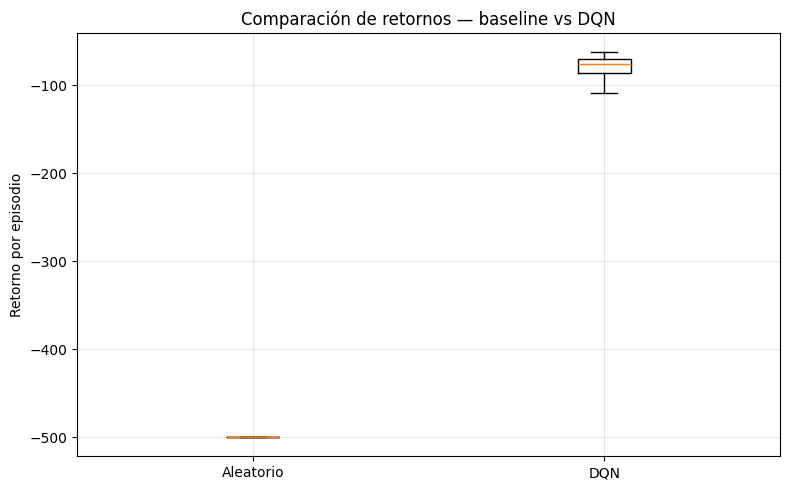

In [10]:
# ============================================================
# 9.1 Comparación cuantitativa: baseline vs DQN
# ============================================================

improvement = dqn_summary["retorno_promedio"] - baseline_summary["retorno_promedio"]
step_reduction = baseline_summary["longitud_promedio"] - dqn_summary["longitud_promedio"]
step_reduction_pct = 100 * step_reduction / baseline_summary["longitud_promedio"]

comparison_df = pd.DataFrame([
    {
        "Agente": "Baseline aleatorio",
        "Retorno promedio": baseline_summary["retorno_promedio"],
        "Desv. estándar": baseline_summary["desviacion_estandar"],
        "Longitud promedio": baseline_summary["longitud_promedio"],
        "Tasa de éxito": baseline_summary["tasa_exito"],
    },
    {
        "Agente": "DQN",
        "Retorno promedio": dqn_summary["retorno_promedio"],
        "Desv. estándar": dqn_summary["desviacion_estandar"],
        "Longitud promedio": dqn_summary["longitud_promedio"],
        "Tasa de éxito": dqn_summary["tasa_exito"],
    },
])
display(comparison_df)

print(f"Mejora absoluta del retorno promedio: {improvement:.2f}")
print(f"Reducción promedio de pasos: {step_reduction:.2f} ({step_reduction_pct:.2f}%)")

plt.figure(figsize=(8, 5))
plt.boxplot([baseline_returns, dqn_returns], tick_labels=["Aleatorio", "DQN"])
plt.title("Comparación de retornos — baseline vs DQN")
plt.ylabel("Retorno por episodio")
plt.grid(alpha=.3)
plt.tight_layout()
plt.savefig(RESULTS_DIR / "comparacion_retornos.png", dpi=300, bbox_inches="tight")
plt.show()


## 10. Resumen cuantitativo y evidencia final

La comparación utiliza el mismo ambiente y separa el entrenamiento de la evaluación determinista. Además de la curva de aprendizaje, se reportan métricas finales sobre 30 episodios y se contrasta el DQN con una política aleatoria.


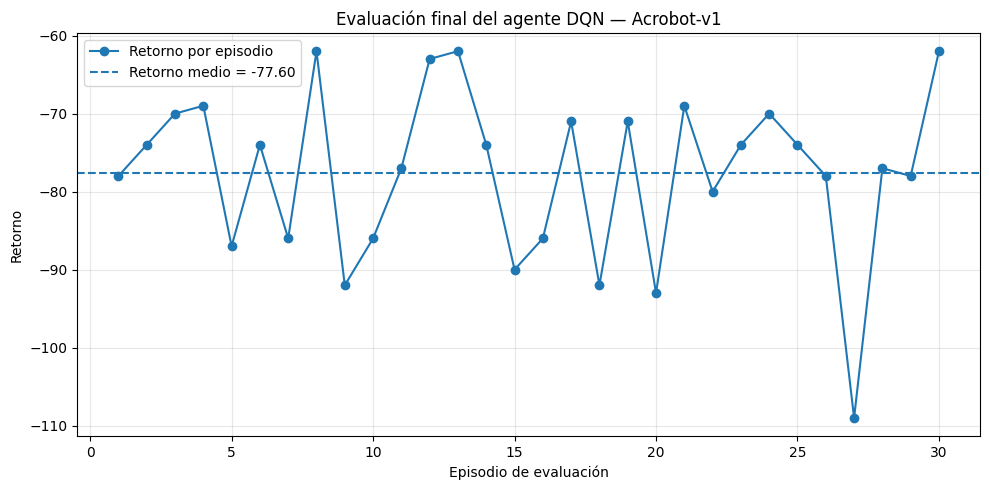

In [11]:
# ============================================================
# 10. Gráfica de evaluación final
# ============================================================

import matplotlib.pyplot as plt

plt.figure(figsize=(10, 5))

plt.plot(
    evaluation_df["episodio"],
    evaluation_df["retorno"],
    marker="o",
    label="Retorno por episodio"
)

plt.axhline(
    returns.mean(),
    linestyle="--",
    label=f"Retorno medio = {returns.mean():.2f}"
)

plt.title("Evaluación final del agente DQN — Acrobot-v1")
plt.xlabel("Episodio de evaluación")
plt.ylabel("Retorno")
plt.legend()
plt.grid(alpha=0.3)
plt.tight_layout()

plt.savefig(
    RESULTS_DIR / "dqn_evaluation.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

## 11. Reflexión de resultados

El agente DQN presenta una mejora sustancial frente al baseline aleatorio. La política aleatoria obtuvo un retorno promedio de **-500.00**, una longitud promedio de **500 pasos** y una tasa de éxito de **0 %**, lo que indica que no alcanzó la meta dentro del límite del episodio. En contraste, la evaluación final del DQN sobre 30 episodios produjo un retorno promedio de **-77.60 ± 10.92**, con valores entre **-109** y **-62**, y una longitud promedio de **78.60 pasos**. La tasa de éxito observada fue **100 %**.

La mejora del retorno promedio es de aproximadamente **422.40 puntos** respecto al baseline y la longitud media del episodio se reduce en cerca de **84.28 %**. Esto es coherente con la función de recompensa de Acrobot: cada paso no terminal penaliza con -1 y alcanzar la meta termina el episodio, por lo que un retorno menos negativo representa una solución más rápida.

La curva de aprendizaje muestra una fase inicial de desempeño pobre y alta variabilidad, seguida por una mejora rápida hasta una región estable de retornos mucho menos negativos. Las fluctuaciones que permanecen son razonables porque el estado inicial es estocástico y algunas configuraciones requieren secuencias distintas de torque para acumular energía. La evaluación final, realizada de manera determinista y separada del entrenamiento, confirma que el comportamiento aprendido generaliza a múltiples reinicios del ambiente.

Como limitaciones, el resultado corresponde a una sola semilla principal de entrenamiento, un presupuesto de 100.000 timesteps y una configuración concreta de hiperparámetros. Por ello, no debe interpretarse como una garantía universal de desempeño. Una evaluación más rigurosa podría repetir el entrenamiento con varias semillas y reportar intervalos de confianza. Aun así, para el objetivo del taller, la diferencia frente al baseline y la estabilidad de la evaluación proporcionan evidencia sólida de aprendizaje.


## 12. Reflexión sobre lo que más costó

Las dificultades principales fueron tanto conceptuales como técnicas. Primero, fue necesario interpretar correctamente la observación de Acrobot: los ángulos no aparecen directamente, sino mediante seno y coseno, junto con las velocidades angulares. Esto obliga a comprender que la red recibe una representación continua de seis dimensiones y no imágenes.

Segundo, al inicio resulta contraintuitivo que el aprendizaje mejore aunque las recompensas sigan siendo negativas. En este ambiente el objetivo no es obtener una gran recompensa positiva, sino reducir el número de pasos necesarios para alcanzar la meta; por eso pasar de **-500** a un retorno promedio cercano a **-77.60** representa una mejora muy grande.

Tercero, fue necesario diferenciar con claridad el papel de cada componente de DQN: la política ε-greedy controla exploración/explotación, el replay buffer desacopla temporalmente las muestras, la red target estabiliza el objetivo de Bellman y la red online es la que se actualiza mediante descenso de gradiente. Confundir cualquiera de estos elementos altera la interpretación del flujo de entrenamiento.

Finalmente, el reto técnico más importante fue mantener un pipeline reproducible: fijar semillas, registrar episodios con `Monitor`, separar entrenamiento y evaluación, evitar mezclar logs de ejecuciones anteriores y conservar únicamente el tramo correspondiente al entrenamiento final de 100.000 timesteps. Esta parte fue necesaria para que la curva presentada realmente representara el experimento final y no una combinación de pruebas previas.


## 13. Generación automática del README
Ejecute esta celda al final. El README usará los resultados reales.

In [12]:
readme = f"""# Taller 2 — DQN sobre Acrobot-v1

## Objetivo
Resolver `Acrobot-v1` mediante Deep Q-Network (DQN) y documentar el proceso de forma reproducible.

## Acciones, observaciones y recompensa
- Observación: `Box(6,)`, `float32`, formada por cos/sin de dos ángulos y dos velocidades angulares.
- Acciones: `Discrete(3)`: torque -1, 0 y +1.
- No se requiere preprocesamiento visual, convoluciones ni frame stacking porque el estado ya es un vector numérico de baja dimensión.
- Recompensa: -1 por cada paso no terminal y 0 al alcanzar la meta; por tanto, un retorno menos negativo implica resolver el episodio en menos pasos.
- Truncación: 500 pasos.

## Flujo DQN
```mermaid
flowchart TD
A[Estado s] --> B[Red Q online]
B --> C[Acción epsilon-greedy]
C --> D[Acrobot-v1]
D --> E[Transición s,a,r,s',done]
E --> F[Replay buffer]
F --> G[Mini-batch]
G --> H[Q online]
G --> I[Red target]
I --> J[Objetivo de Bellman]
H --> K[Pérdida TD]
J --> K
K --> L[Backpropagation]
L --> B
L -. sincronización periódica .-> I
```

## Particularidades del ambiente
El estado es continuo y de baja dimensión, las acciones son discretas y la recompensa penaliza el número de pasos. La solución exige acumular energía mediante oscilaciones, por lo que la exploración epsilon-greedy es especialmente importante al comienzo.

## Red neuronal e hiperparámetros
Arquitectura: **6 → 256 ReLU → 256 ReLU → 3 valores Q**. La MLP es adecuada porque la observación es vectorial y la salida debe producir un valor Q para cada una de las tres acciones.

| Hiperparámetro | Valor |
|---|---:|
| Learning rate | {HYPERPARAMS['learning_rate']} |
| Replay buffer | {HYPERPARAMS['buffer_size']} |
| Learning starts | {HYPERPARAMS['learning_starts']} |
| Batch size | {HYPERPARAMS['batch_size']} |
| Gamma | {HYPERPARAMS['gamma']} |
| Target update interval | {HYPERPARAMS['target_update_interval']} |
| Train frequency | {HYPERPARAMS['train_freq']} |
| Gradient steps | {HYPERPARAMS['gradient_steps']} |
| Exploration fraction | {HYPERPARAMS['exploration_fraction']} |
| Epsilon inicial/final | {HYPERPARAMS['exploration_initial_eps']} / {HYPERPARAMS['exploration_final_eps']} |
| Timesteps | {HYPERPARAMS['total_timesteps']} |

## Resultados
![Curva de aprendizaje](results/dqn_learning_curve.png)

![Evaluación final](results/dqn_evaluation.png)

![Comparación baseline vs DQN](results/comparacion_retornos.png)

| Métrica | Baseline aleatorio | DQN |
|---|---:|---:|
| Retorno promedio | {baseline_summary['retorno_promedio']:.2f} | {dqn_summary['retorno_promedio']:.2f} |
| Desv. estándar | {baseline_summary['desviacion_estandar']:.2f} | {dqn_summary['desviacion_estandar']:.2f} |
| Longitud promedio | {baseline_summary['longitud_promedio']:.2f} | {dqn_summary['longitud_promedio']:.2f} |
| Tasa de éxito | {baseline_summary['tasa_exito']*100:.1f}% | {dqn_summary['tasa_exito']*100:.1f}% |

La mejora del retorno promedio fue de **{improvement:.2f} puntos**. El DQN redujo la longitud media de los episodios en **{step_reduction:.2f} pasos ({step_reduction_pct:.2f}%)** respecto al baseline.

## Reflexión de resultados
El baseline aleatorio no resolvió el ambiente, mientras que el DQN alcanzó retornos considerablemente menos negativos y una tasa de éxito alta. La curva de aprendizaje muestra una transición desde episodios muy largos hacia una región estable de mejor desempeño. Las fluctuaciones restantes se relacionan con la condición inicial estocástica y con la necesidad de acumular energía mediante secuencias de torque. El resultado está condicionado por la semilla, el presupuesto de entrenamiento y los hiperparámetros; por ello, una extensión rigurosa sería repetir el experimento con varias semillas.

## Reflexión sobre lo que más costó
Los retos principales fueron interpretar la representación seno/coseno del estado, comprender el significado de una recompensa negativa, distinguir el papel de replay buffer, epsilon-greedy, red target y Bellman, y asegurar que los logs y la curva correspondieran únicamente al entrenamiento final. La reproducibilidad exigió semillas, Monitor, evaluación determinista y separación clara entre entrenamiento y evaluación.

## Reproducibilidad
1. `pip install \"gymnasium[classic-control]\" \"stable-baselines3[extra]\"`
2. Ejecutar `Taller2_DQN_Acrobot.ipynb` de arriba hacia abajo.
3. El modelo queda en `models/` y las métricas/figuras en `results/`.

## Referencias
- Gymnasium — `Acrobot-v1`.
- Mnih et al. (2015), *Human-level control through deep reinforcement learning*.
- Stable-Baselines3 — DQN.
- RL Baselines3 Zoo — hiperparámetros DQN.
"""

with open("README.md", "w", encoding="utf-8") as f:
    f.write(readme)

print("README.md generado correctamente.")


README.md generado correctamente.


## 14. Checklist final antes de subir a GitHub
- [x] Acciones y observaciones: tipo, dimensiones, dtype, recompensa y justificación.
- [x] Flujo completo DQN: replay buffer, ε-greedy, red target y Bellman.
- [x] Particularidades del ambiente claramente separadas.
- [x] Arquitectura con dimensiones e hiperparámetros justificados.
- [x] Métricas concretas + curva de aprendizaje + evaluación final.
- [x] Reflexión profunda de resultados y limitaciones.
- [x] Dificultades conceptuales y técnicas.
- [x] Notebook ejecutado de inicio a fin sin errores de ejecución.
- [x] README generado al final.
- [ ] Subir `README.md`, el notebook, `results/` y los archivos requeridos al repositorio público de GitHub.
